**Why Business Leaders Don't Buy "Black Boxes"**

- The Accuracy of your model does not impress stakeholders

- A 95% model accuracy is worthless to a business stakeholder if they cannot understand why it makes such decisions.

- They don't trust it; it lacks clarity; it lacks actionable business insights

- Data Visualization acts as the translation layer across the entire ML pipeline

**Business-Valued ML Visualization**

- Phase 1: Risk & Data Quality: There is a business problem of corrupted, heavily skewed, and incomplete data.

- Solution: Visualize the errors, extreme outliers, missing information...

- Phase 2: ROI & Lever Discoveries: There is a business problem of investing in factors that won't impact their goals & preferred outcomes

- Solution: Visualizing how spending directly impacts their Return On Investment.

- Phase 3: Model Auditing & Trust: Business problem is knowing the cost of the model's mistakes.

- Solution: Visualizing model errors in simple business terms

**Real-World Scenario: You are advising the State Department of Education. They need to allocate $50 Million intervention fund to imporove student performance(Math Proficiency)**

**Step 1: Setup Environment & Data Ingestion**

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Clean & Professional Visual Aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('muted')

# Ingest US Education System Dataset (Robust path for local & Colab runtimes)
dataset_path = 'us_education_system_dataset.csv'
if not os.path.exists(dataset_path):
    dataset_path = '/content/drive/MyDrive/Data/us_education_system_dataset.csv'

us_edu_data = pd.read_csv(dataset_path)


In [4]:
#plt.style.available

In [5]:
allocation_data = us_edu_data[['institution_name', 'level', 'control',
             'title_i_status', 'per_pupil_expenditure_usd',
             'percent_free_reduced_lunch', 'math_proficiency_pct']]

In [6]:
allocation_data.head()

,institution_name,level,control,title_i_status,per_pupil_expenditure_usd,percent_free_reduced_lunch,math_proficiency_pct
0,Jefferson Elementary School,Elementary School,Public,Title I Schoolwide,12840,48.9,58.3
1,Lakeshore Middle School,Middle School,Private Religious,Not Applicable,17009,1.2,84.8
2,Meadowbrook Elementary Academy,Elementary School,Private For-Profit,Not Applicable,15374,36.0,54.6
3,Roosevelt Primary School,Elementary School,Public,Not Title I Eligible,17065,15.1,66.1
4,Highland Park Primary School,Elementary School,Public,Title I Targeted,16823,45.6,54.6


**Step 2: Resource Allocation Audit**

- Business Insight: Leadership must understand how funds are currently distributed across institutions.

- Are funds evenly spread, or concentrated in specific school types?

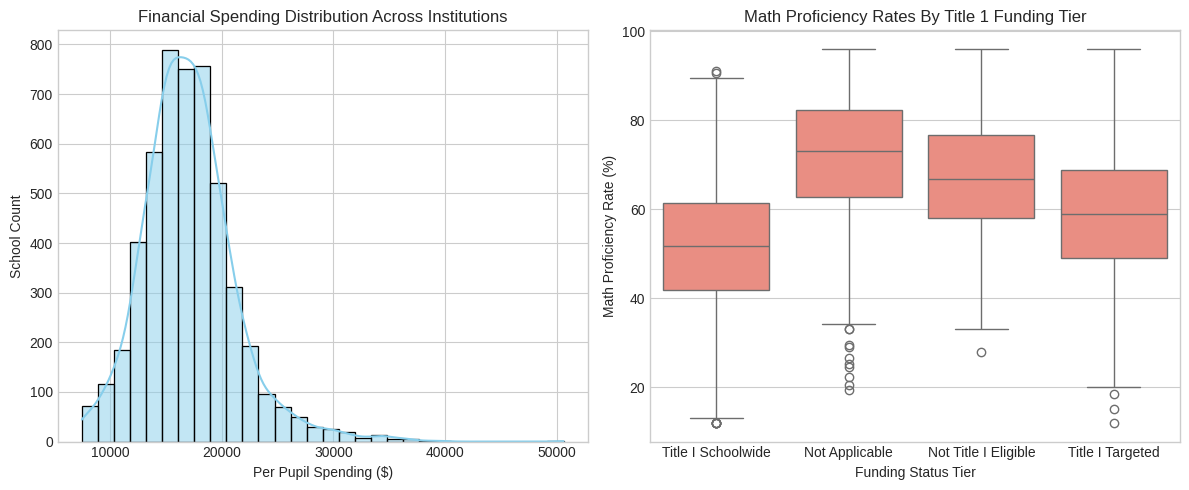

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Show financial distribution skewness
sns.histplot(allocation_data['per_pupil_expenditure_usd'], kde=True,
             ax=axes[0], color='skyblue', bins=30)
axes[0].set_title('Financial Spending Distribution Across Institutions')
axes[0].set_xlabel('Per Pupil Spending ($)')
axes[0].set_ylabel('School Count')

# Plot 2: Performance Across Funding Eligibility
sns.boxplot(data=allocation_data, x='title_i_status', y='math_proficiency_pct',
            ax=axes[1], color='salmon')
axes[1].set_title('Math Proficiency Rates By Title 1 Funding Tier')
axes[1].set_xlabel('Funding Status Tier')
axes[1].set_ylabel('Math Proficiency Rate (%)')
plt.tight_layout()
plt.show()

### 📈 Executive Interpretation & Strategic Audit Insights

#### 1. Financial Spending Distribution Across Institutions
- **The Clustered Baseline (,000 – ,000):** The vast majority of schools operate within a baseline funding envelope peaking around **,000–,000** per pupil.
- **The High-Spending Right Skew (,000 – ,000+):** A small fraction of institutions spend 2x to 3x more per student, driven by local wealth disparities, specialized programs, or private endowments.
- **Audit Implication:** Uniform funding increases will disproportionately reward already affluent districts without solving baseline inadequacies.

#### 2. Math Proficiency Rates Across Title 1 Funding Tiers
- **The Structural Achievement Deficit:**
  - **Title I Schoolwide (Deepest Poverty):** Median math proficiency is only **~51%** (middle 50% between 42%–61%).
  - **Title I Targeted (Moderate Poverty):** Median math proficiency rises to **~59%**.
  - **Not Title I Eligible (Low Poverty / Wealthier):** Median math proficiency reaches **~67%** (IQR 58%–77%).
  - **Not Applicable (Colleges / Private):** Median proficiency tops at **~73%**.
- **The 16-to-22 Percentage Point Gap:** Despite receiving federal supplemental aid, schools serving the highest concentrations of economically disadvantaged students significantly lag non-eligible schools. Title I status currently acts as a **marker of high systemic need**, rather than an equalizer.
- **Positive Outliers ("Beat-the-Odds" Institutions):** Several Title I Schoolwide institutions defy socioeconomic barriers to attain 80%+ math proficiency, offering high-value blueprints for pedagogical best practices.

---

### 🎯 Strategic Blueprint: Allocating the  Million Intervention Fund

To maximize Return on Investment (ROI) and measurably improve math proficiency, the M fund should be allocated across four evidence-based pillars:

1. **Weighted Student Funding Allocation (M / 40%):**
   - Shift from flat-rate distribution to a needs-weighted formula targeting Title I Schoolwide institutions to balance baseline expenditure disparities.
2. **High-Dosage Math Tutoring (M / 30%):**
   - Implement intensive, in-school small-group (1:3 ratio) tutoring in Title I schools, proven to deliver 2x to 3x standard academic year gains.
3. **Master Teacher Retention & Incentive Stipends (M / 20%):**
   - Provide retention bonuses and mentorship reduced loads to keep experienced math educators in high-poverty classrooms.
4. **Foundational Numeracy & Diagnostic Screening (M / 10%):**
   - Deploy early numeracy screening and intervention toolkits in elementary feeders to resolve math learning gaps before high school.
